In [32]:
!pip install mitsuba

In [33]:
import mitsuba as mi
import matplotlib.pyplot as plt
import math

In [ ]:
mi.set_variant('cuda_ad_spectral')

In [ ]:
from typing import Optional

def make_sensor(width : int, height : int, wave_length: Optional[float] = None) -> mi.Sensor:
    base = {
        'type': 'perspective',
        'fov': 70,
        'to_world': mi.ScalarTransform4f.look_at(
            origin=[0, 0, 4],
            target=[0, 0, 0],
            up=[0, 1, 0],
        ),
    }
    if wave_length is None:
        film = {'type': 'hdrfilm', 'width': width, 'height': height}
    else:
        film = {
            'type': 'specfilm',
            'width': width,
            'height': height,
            'channel1': {
                'type': 'irregular',
                'wavelengths': f'{wave_length}, {wave_length + 1}',
                'values': '1.0, 1.0',
            },
        }

    return mi.load_dict({**base, 'film': film})

In [ ]:
scene = mi.load_dict(mi.cornell_box())

images = dict()
for wave_length in range(380, 780, 40):
    images[wave_length] = mi.render(scene, sensor=make_sensor(1920, 1080, wave_length), spp=256)
images['rgb'] = mi.render(scene, sensor=make_sensor(1920,1080), spp=256)

In [30]:
import numpy as np
import math
import matplotlib.pyplot as plt

def show_images(images: dict, gamma: float = 2.2, cols: int = 4, cmap=None):
    items = list(images.items())
    n = len(items)
    cols = min(cols, n)
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows), squeeze=False)

    for ax, (title, image) in zip(axes.flat, items):
        img = np.asarray(image, dtype=np.float64)

        img = np.clip(img, 0.0, 1.0)

        img_g = np.power(img, 1.0 / gamma)

        ax.imshow(img_g, cmap=cmap, vmin=0.0, vmax=1.0)
        ax.set_title(title)
        ax.axis("off")

    for ax in axes.flat[n:]:
        ax.axis("off")

    fig.tight_layout()
    plt.show()

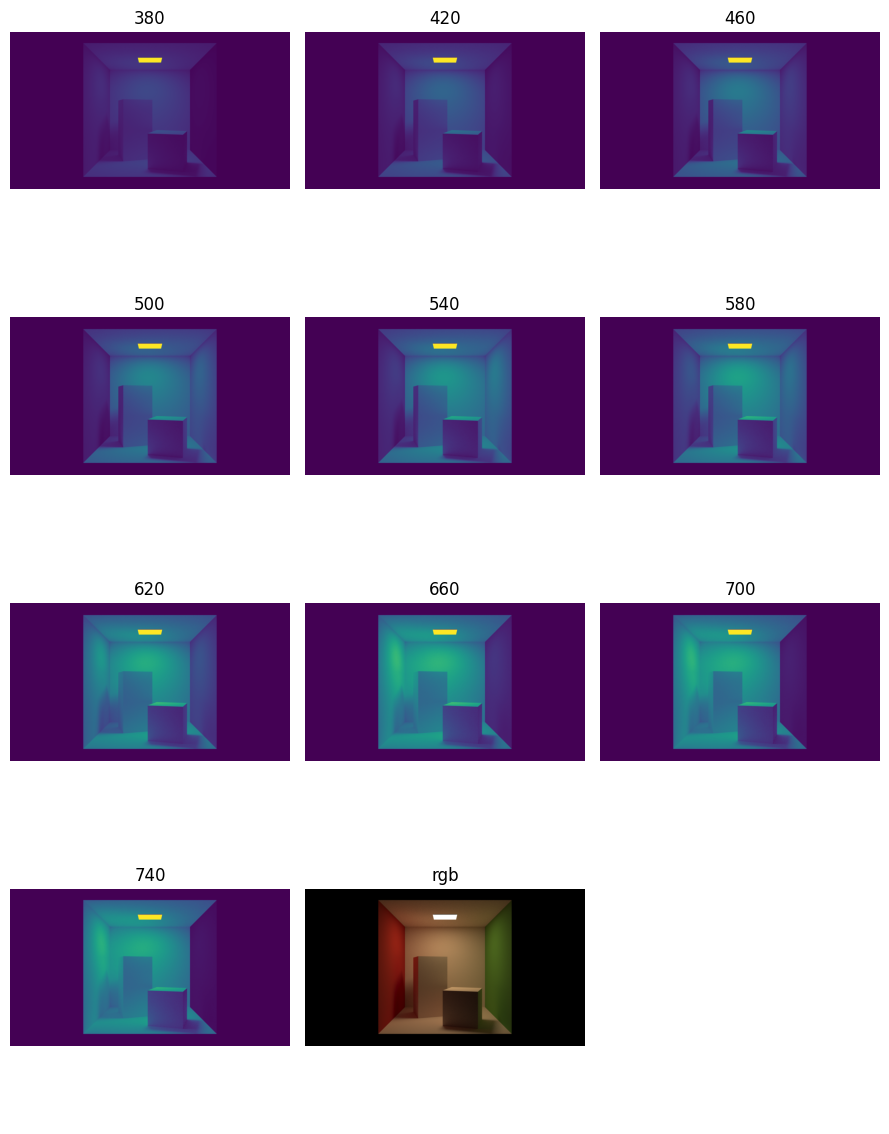

In [31]:
show_images(images, cols=3) 